In [1]:
# ============================================================
# ZEPTO INVENTORY & PRICING ANALYTICS
# Python Data Cleaning + Feature Engineering + EDA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

# ------------------------------------------------------------
# Load raw Excel file
# ------------------------------------------------------------

file_path = r"C:\Data Analyst\Retail Projects\Zepto Inventory\zepto_v1.xlsx"

df = pd.read_excel(file_path)

print("DATASET LOADED SUCCESSFULLY")
print("=" * 50)
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nData Types:")
df.info()

DATASET LOADED SUCCESSFULLY
Rows    : 3,732
Columns : 9

Column Names:
['Category', 'name', 'mrp', 'discountPercent', 'availableQuantity', 'discountedSellingPrice', 'weightInGms', 'outOfStock', 'quantity']

First 5 Records:


,Category,name,mrp,discountPercent,availableQuantity,discountedSellingPrice,weightInGms,outOfStock,quantity
0,Fruits & Vegetables,Onion,2500,16,3,2100,1000,False,1
1,Fruits & Vegetables,Tomato Hybrid,4200,16,3,3500,1000,False,1
2,Fruits & Vegetables,Tender Coconut,5100,15,3,4300,58,False,1
3,Fruits & Vegetables,Coriander Leaves,2000,15,3,1700,100,False,100
4,Fruits & Vegetables,Ladies Finger,1400,14,3,1200,250,False,250



Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 3732 entries, 0 to 3731
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Category                3732 non-null   str  
 1   name                    3732 non-null   str  
 2   mrp                     3732 non-null   int64
 3   discountPercent         3732 non-null   int64
 4   availableQuantity       3732 non-null   int64
 5   discountedSellingPrice  3732 non-null   int64
 6   weightInGms             3732 non-null   int64
 7   outOfStock              3732 non-null   bool 
 8   quantity                3732 non-null   int64
dtypes: bool(1), int64(6), str(2)
memory usage: 237.0 KB


In [2]:
# ============================================================
# DATA QUALITY CHECK
# ============================================================

print("1. MISSING VALUES")
print("=" * 50)

missing_report = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_%': (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_report)


print("\n2. DUPLICATE CHECK")
print("=" * 50)

duplicate_count = df.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_count:,}")


print("\n3. UNIQUE VALUES")
print("=" * 50)

unique_report = pd.DataFrame({
    'Column': df.columns,
    'Unique_Values': [df[col].nunique() for col in df.columns]
})

display(unique_report)


print("\n4. STATISTICAL SUMMARY")
print("=" * 50)

display(df.describe(include='all').T)

1. MISSING VALUES


,Missing_Count,Missing_%
Category,0,0.00
name,0,0.00
mrp,0,0.00
discountPercent,0,0.00
availableQuantity,0,0.00
discountedSellingPrice,0,0.00
weightInGms,0,0.00
outOfStock,0,0.00
quantity,0,0.00



2. DUPLICATE CHECK
Exact duplicate rows: 2

3. UNIQUE VALUES


,Column,Unique_Values
0,Category,14
1,name,1681
2,mrp,266
3,discountPercent,42
4,availableQuantity,7
5,discountedSellingPrice,350
6,weightInGms,158
7,outOfStock,2
8,quantity,143



4. STATISTICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Category,3732,14,Cooking Essentials,514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,3732,1681,Arden Eggs White,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mrp,"3,732.00",NaN,NaN,NaN,"15,680.12","16,088.81",0.00,"6,000.00","11,000.00","20,000.00","260,000.00"
discountPercent,"3,732.00",NaN,NaN,NaN,7.62,9.21,0.00,0.00,6.00,10.00,51.00
availableQuantity,"3,732.00",NaN,NaN,NaN,4.01,2.20,0.00,2.00,5.00,6.00,6.00
discountedSellingPrice,"3,732.00",NaN,NaN,NaN,"14,192.83","13,850.73",0.00,"5,500.00","10,400.00","18,400.00","139,900.00"
weightInGms,"3,732.00",NaN,NaN,NaN,387.84,678.10,0.00,100.00,225.00,450.00,"10,000.00"
outOfStock,3732,2,False,3279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,"3,732.00",NaN,NaN,NaN,213.27,194.73,0.00,50.00,186.00,340.00,"1,500.00"


In [3]:
# ============================================================
# STANDARDIZE COLUMN NAMES
# ============================================================

df = df.rename(columns={
    'name': 'Product_Name',
    'category': 'Category',
    'mrp': 'MRP',
    'discountPercent': 'Discount_Percent',
    'availableQuantity': 'Available_Quantity',
    'discountedSellingPrice': 'Selling_Price',
    'weightInGms': 'Weight_Gms',
    'outOfStock': 'Out_of_Stock',
    'quantity': 'Quantity'
})

# ------------------------------------------------------------
# Clean text columns
# ------------------------------------------------------------

df['Product_Name'] = (
    df['Product_Name']
    .astype(str)
    .str.strip()
)

df['Category'] = (
    df['Category']
    .astype(str)
    .str.strip()
)

df['Out_of_Stock'] = (
    df['Out_of_Stock']
    .astype(str)
    .str.strip()
    .str.lower()
)

# ------------------------------------------------------------
# Convert numerical columns
# ------------------------------------------------------------

numeric_columns = [
    'MRP',
    'Discount_Percent',
    'Available_Quantity',
    'Selling_Price',
    'Weight_Gms',
    'Quantity'
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors='coerce'
    )

print("Column names after standardization:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Column names after standardization:
['Category', 'Product_Name', 'MRP', 'Discount_Percent', 'Available_Quantity', 'Selling_Price', 'Weight_Gms', 'Out_of_Stock', 'Quantity']

Data types:
Category                str
Product_Name            str
MRP                   int64
Discount_Percent      int64
Available_Quantity    int64
Selling_Price         int64
Weight_Gms            int64
Out_of_Stock            str
Quantity              int64
dtype: object


In [4]:
# ============================================================
# BUSINESS DATA VALIDATION
# ============================================================

print("BUSINESS VALIDATION")
print("=" * 50)

# Negative values
print("\nNegative values:")
for column in numeric_columns:
    count = (df[column] < 0).sum()
    print(f"{column}: {count}")

# Selling price greater than MRP
invalid_price = df[
    df['Selling_Price'] > df['MRP']
]

print(
    f"\nSelling Price > MRP: "
    f"{len(invalid_price):,} rows"
)

# Zero / missing MRP
invalid_mrp = df[
    df['MRP'].isna() | (df['MRP'] <= 0)
]

print(
    f"Invalid MRP: "
    f"{len(invalid_mrp):,} rows"
)

# Zero / negative selling price
invalid_selling_price = df[
    df['Selling_Price'].isna() |
    (df['Selling_Price'] <= 0)
]

print(
    f"Invalid Selling Price: "
    f"{len(invalid_selling_price):,} rows"
)

# Discount validation
calculated_discount = np.where(
    df['MRP'] > 0,
    ((df['MRP'] - df['Selling_Price']) /
     df['MRP']) * 100,
    np.nan
)

df['Calculated_Discount_%'] = calculated_discount.round(2)

df['Discount_Difference'] = (
    df['Calculated_Discount_%'] -
    df['Discount_Percent']
).abs().round(2)

print(
    "\nMaximum difference between "
    "source discount and calculated discount:",
    df['Discount_Difference'].max()
)

BUSINESS VALIDATION

Negative values:
MRP: 0
Discount_Percent: 0
Available_Quantity: 0
Selling_Price: 0
Weight_Gms: 0
Quantity: 0

Selling Price > MRP: 0 rows
Invalid MRP: 1 rows
Invalid Selling Price: 1 rows

Maximum difference between source discount and calculated discount: 0.99


In [5]:
# ============================================================
# PRODUCT-CATEGORY CONSISTENCY CHECK
# ============================================================

product_category_check = (
    df.groupby('Product_Name')['Category']
      .nunique()
      .reset_index(name='Category_Count')
)

category_conflicts = (
    product_category_check[
        product_category_check['Category_Count'] > 1
    ]
    .sort_values(
        'Category_Count',
        ascending=False
    )
)

conflict_products = (
    category_conflicts['Product_Name']
    .tolist()
)

conflict_rows = df[
    df['Product_Name'].isin(conflict_products)
]

print(
    "Products assigned to multiple categories:",
    len(category_conflicts)
)

print(
    "Rows affected:",
    len(conflict_rows)
)

print("\nExamples:")
display(
    conflict_rows[
        ['Product_Name', 'Category']
    ]
    .drop_duplicates()
    .head(30)
)

Products assigned to multiple categories: 1185
Rows affected: 3212

Examples:


,Product_Name,Category
81,Safal Frozen - Mixed Vegetables,Fruits & Vegetables
90,Safal Frozen Mixed Vegetables,Fruits & Vegetables
91,Safal Frozen Corn,Fruits & Vegetables
92,Safal Frozen - Sweet Corn,Fruits & Vegetables
93,Maggi 2 Minute Masala Noodles,Cooking Essentials
94,iD Idli & Dosa Batter,Cooking Essentials
95,Tata Salt,Cooking Essentials
96,Arden Eggs White,Cooking Essentials
98,Fortune Sunlite Refined Sunflower (Pouch),Cooking Essentials
99,Aashirvaad Superior MP Atta,Cooking Essentials


In [6]:
# ============================================================
# PRODUCT CATEGORY CLASSIFICATION
# ============================================================

def correct_category(product_name):

    product = str(product_name).lower()

    # --------------------------------------------------------
    # Fruits & Vegetables
    # --------------------------------------------------------
    if any(k in product for k in [
        'apple', 'banana', 'mango', 'orange', 'grapes',
        'papaya', 'guava', 'pineapple', 'watermelon',
        'pomegranate', 'kiwi', 'lemon', 'lime',
        'tomato', 'potato', 'onion', 'carrot', 'cucumber',
        'capsicum', 'spinach', 'palak', 'broccoli',
        'cauliflower', 'cabbage', 'beetroot', 'radish',
        'ginger', 'garlic', 'green chilli', 'chilli',
        'coriander', 'mint', 'peas', 'corn',
        'coconut', 'coccinia', 'zucchini', 'lettuce',
        'methi', 'muskmelon', 'sapota', 'amla',
        'beans', 'lady finger', 'ladies finger',
        'okra', 'pumpkin', 'avocado', 'dragon fruit',
        'ridge gourd', 'sponge gourd', 'colocasia',
        'parsley', 'basil', 'mixed sprouts',
        'sprouts', 'brinjal'
    ]):
        return 'Fruits & Vegetables'

    # --------------------------------------------------------
    # Meats, Fish & Eggs
    # --------------------------------------------------------
    elif any(k in product for k in [
        'chicken', 'mutton', 'fish', 'prawn', 'prawns',
        'egg', 'eggs', 'seafood', 'rohu', 'pomfret',
        'surmai', 'salmon', 'tuna', 'crab',
        'meat', 'lamb', 'goat'
    ]):
        return 'Meats, Fish & Eggs'

    # --------------------------------------------------------
    # Pet products - no suitable source category
    # --------------------------------------------------------
    elif any(k in product for k in [
        'whiskas', 'cat food', 'dog food', 'pedigree',
        'pet food'
    ]):
        return 'Needs Review'

    # --------------------------------------------------------
    # Personal Care
    # --------------------------------------------------------
    elif any(k in product for k in [
        'shampoo', 'conditioner', 'soap', 'body wash',
        'face wash', 'face cream', 'moisturizer',
        'lotion', 'deodorant', 'perfume', 'toothpaste',
        'toothbrush', 'razor', 'shaving', 'hair oil',
        'hair color', 'sunscreen', 'lip balm',
        'serum', 'cleanser', 'hand wash',
        'body lotion'
    ]):
        return 'Personal Care'

    # --------------------------------------------------------
    # Health & Hygiene
    # --------------------------------------------------------
    elif any(k in product for k in [
        'vitamin', 'supplement', 'medicine', 'sanitizer',
        'mask', 'bandage', 'antiseptic', 'pain relief',
        'health', 'hygiene', 'multivitamin'
    ]):
        return 'Health & Hygiene'

    # --------------------------------------------------------
    # Home & Cleaning
    # --------------------------------------------------------
    elif any(k in product for k in [
        'detergent', 'dishwash', 'dish wash',
        'floor cleaner', 'toilet cleaner',
        'surface cleaner', 'cleaner',
        'washing powder', 'fabric conditioner',
        'phenyl', 'broom', 'mop', 'cleaning',
        'garbage bag', 'tissue', 'paper towel'
    ]):
        return 'Home & Cleaning'

    # --------------------------------------------------------
    # Biscuits
    # --------------------------------------------------------
    elif any(k in product for k in [
        'biscuit', 'biscuits', 'cookie', 'cookies',
        'cracker', 'crackers'
    ]):
        return 'Biscuits'

    # --------------------------------------------------------
    # Chocolates & Candies
    # --------------------------------------------------------
    elif any(k in product for k in [
        'chocolate', 'chocolates', 'candy', 'candies',
        'toffee', 'toffees', 'lollipop', 'gummy',
        'kitkat', 'dairy milk', '5 star', 'perk'
    ]):
        return 'Chocolates & Candies'

    # --------------------------------------------------------
    # Ice Cream & Desserts
    # --------------------------------------------------------
    elif any(k in product for k in [
        'ice cream', 'icecream', 'kulfi', 'dessert',
        'brownie', 'cake', 'pastry', 'gulab jamun',
        'rasgulla', 'jalebi', 'kheer', 'halwa'
    ]):
        return 'Ice Cream & Desserts'

    # --------------------------------------------------------
    # Munchies
    # --------------------------------------------------------
    elif any(k in product for k in [
        'chips', 'namkeen', 'bhujia', 'mixture',
        'popcorn', 'nachos', 'sev', 'snacks',
        'munchies', 'kurkure', 'lays'
    ]):
        return 'Munchies'

    # --------------------------------------------------------
    # Dairy, Bread & Batter
    # --------------------------------------------------------
    elif any(k in product for k in [
        'milk', 'paneer', 'cheese', 'butter',
        'curd', 'yogurt', 'cream',
        'bread', 'bun', 'batter',
        'paratha', 'chapati', 'roti',
        'naan', 'dosa', 'idli'
    ]):
        return 'Dairy, Bread & Batter'

    # --------------------------------------------------------
    # Cooking Essentials
    # --------------------------------------------------------
    elif any(k in product for k in [
        'atta', 'flour', 'maida', 'besan',
        'rice', 'dal', 'pulses', 'sugar',
        'salt', 'oil', 'masala', 'spice',
        'spices', 'cumin', 'jeera', 'pepper',
        'turmeric', 'haldi', 'chilli powder',
        'jaggery', 'ghee', 'poha', 'sooji',
        'rava', 'semolina', 'noodles', 'pasta',
        'maggi', 'vermicelli', 'baking soda',
        'almond', 'cashew', 'peanut',
        'seed', 'seeds', 'dates',
        'ajwain', 'saunf', 'fennel',
        'groundnut', 'mustard'
    ]):
        return 'Cooking Essentials'

    # --------------------------------------------------------
    # Beverages
    # --------------------------------------------------------
    elif any(k in product for k in [
        'juice', 'drink', 'beverage', 'cola',
        'sprite', 'pepsi', 'coke',
        'coca cola', 'water', 'energy drink',
        'coffee', 'tea', 'green tea',
        'cold coffee', 'shake', 'smoothie'
    ]):
        return 'Beverages'

    # --------------------------------------------------------
    # Packaged Food
    # --------------------------------------------------------
    elif any(k in product for k in [
        'muesli', 'corn flakes', 'cereal',
        'oats', 'ready to eat', 'instant food',
        'pickle', 'sauce', 'ketchup', 'jam',
        'spread', 'peanut butter'
    ]):
        return 'Packaged Food'

    # --------------------------------------------------------
    # Unknown
    # --------------------------------------------------------
    else:
        return 'Needs Review'


df['Corrected_Category'] = (
    df['Product_Name']
    .apply(correct_category)
)

print("Corrected category created successfully.")
display(
    df[
        ['Product_Name', 'Category',
         'Corrected_Category']
    ].head(20)
)

Corrected category created successfully.


,Product_Name,Category,Corrected_Category
0,Onion,Fruits & Vegetables,Fruits & Vegetables
1,Tomato Hybrid,Fruits & Vegetables,Fruits & Vegetables
2,Tender Coconut,Fruits & Vegetables,Fruits & Vegetables
3,Coriander Leaves,Fruits & Vegetables,Fruits & Vegetables
4,Ladies Finger,Fruits & Vegetables,Fruits & Vegetables
5,Potato,Fruits & Vegetables,Fruits & Vegetables
6,Lemon,Fruits & Vegetables,Fruits & Vegetables
7,Watermelon,Fruits & Vegetables,Fruits & Vegetables
8,Capsicum Green,Fruits & Vegetables,Fruits & Vegetables
9,Chilli Green,Fruits & Vegetables,Fruits & Vegetables


In [7]:
# ============================================================
# CATEGORY QUALITY REPORT
# ============================================================

needs_review = (
    df[
        df['Corrected_Category'] == 'Needs Review'
    ][
        ['Product_Name', 'Category']
    ]
    .drop_duplicates()
)

print(
    "Unique products needing review:",
    needs_review['Product_Name'].nunique()
)

print("\nExamples:")
display(needs_review.head(50))

# Category comparison
category_comparison = pd.DataFrame({
    'Original_Count':
        df['Category'].value_counts(),
    'Corrected_Count':
        df['Corrected_Category'].value_counts()
}).fillna(0).astype(int)

print("\nCategory comparison:")
display(category_comparison)

Unique products needing review: 473

Examples:


,Product_Name,Category
25,Bottle Gourd,Fruits & Vegetables
28,Curry Leaves,Fruits & Vegetables
33,Bitter Gourd,Fruits & Vegetables
68,Pear Green Imported,Fruits & Vegetables
72,Biryani /Pulav Mix,Fruits & Vegetables
81,Safal Frozen - Mixed Vegetables,Fruits & Vegetables
90,Safal Frozen Mixed Vegetables,Fruits & Vegetables
98,Fortune Sunlite Refined Sunflower (Pouch),Cooking Essentials
104,Fortune Sunlite Refined Sunflower (Jar),Cooking Essentials
116,Tata Sampann kabuli chana,Cooking Essentials



Category comparison:


,Original_Count,Corrected_Count
Beverages,129,29
Biscuits,147,70
Chocolates & Candies,388,56
Cooking Essentials,514,807
"Dairy, Bread & Batter",129,357
Fruits & Vegetables,93,577
Health & Hygiene,97,41
Home & Cleaning,194,54
Ice Cream & Desserts,388,39
"Meats, Fish & Eggs",63,241


In [8]:
# ============================================================
# REMOVE REPEATED PRODUCT RECORDS
# ============================================================

before_rows = len(df)

# Business attributes that should identify the same
# inventory/product observation in this snapshot.
dedup_columns = [
    'Product_Name',
    'MRP',
    'Selling_Price',
    'Available_Quantity',
    'Weight_Gms',
    'Quantity',
    'Corrected_Category'
]

# Remove repeated records
df = (
    df
    .drop_duplicates(
        subset=dedup_columns,
        keep='first'
    )
    .reset_index(drop=True)
)

after_rows = len(df)

print("DUPLICATE / REPEATED PRODUCT CLEANING")
print("=" * 50)
print(f"Rows before cleaning : {before_rows:,}")
print(f"Rows after cleaning  : {after_rows:,}")
print(f"Rows removed         : {before_rows - after_rows:,}")

DUPLICATE / REPEATED PRODUCT CLEANING
Rows before cleaning : 3,732
Rows after cleaning  : 1,801
Rows removed         : 1,931


In [9]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

# Discount amount
df['Discount_Amount'] = (
    df['MRP'] - df['Selling_Price']
).round(2)

# Discount percentage
df['Discount_%'] = np.where(
    df['MRP'] > 0,
    (df['Discount_Amount'] / df['MRP']) * 100,
    0
).round(2)

# Potential revenue
df['Potential_Revenue'] = (
    df['Selling_Price'] * df['Quantity']
).round(2)

# Current stock value
df['Stock_Value'] = (
    df['Selling_Price'] *
    df['Available_Quantity']
).round(2)

# Weight in KG
df['Weight_KG'] = (
    df['Weight_Gms'] / 1000
).round(3)

print("Feature engineering completed.")

Feature engineering completed.


In [10]:
# ============================================================
# BUSINESS CLASSIFICATION
# ============================================================

# Stock Status
def get_stock_status(quantity):
    if quantity <= 0:
        return 'Out of Stock'
    elif quantity <= 5:
        return 'Low Stock'
    elif quantity <= 20:
        return 'Medium Stock'
    else:
        return 'Healthy Stock'


df['Stock_Status'] = (
    df['Available_Quantity']
    .apply(get_stock_status)
)


# Discount Band
def get_discount_band(discount):
    if discount < 10:
        return '0-10%'
    elif discount < 20:
        return '10-20%'
    elif discount < 30:
        return '20-30%'
    else:
        return '30%+'


df['Discount_Band'] = (
    df['Discount_%']
    .apply(get_discount_band)
)


# Price Band
df['Price_Band'] = pd.qcut(
    df['Selling_Price'],
    q=4,
    labels=[
        'Budget',
        'Mid-Range',
        'Premium',
        'High-End'
    ],
    duplicates='drop'
)


# Availability
df['Availability_Flag'] = np.where(
    df['Available_Quantity'] > 0,
    'Available',
    'Unavailable'
)


print("Business classification completed.")

Business classification completed.


In [11]:
# ============================================================
# FINAL DATA QUALITY CHECK
# ============================================================

print("FINAL DATA QUALITY REPORT")
print("=" * 60)

print(f"Total rows              : {len(df):,}")
print(f"Total columns           : {len(df.columns)}")
print(f"Duplicate rows          : {df.duplicated().sum():,}")

print(
    f"Unique products         : "
    f"{df['Product_Name'].nunique():,}"
)

print("\nMissing values:")
display(
    df.isnull()
      .sum()
      .to_frame('Missing_Count')
)


print("\nCorrected categories:")
display(
    df['Corrected_Category']
      .value_counts()
      .to_frame('Product_Count')
)

FINAL DATA QUALITY REPORT
Total rows              : 1,801
Total columns           : 21
Duplicate rows          : 0
Unique products         : 1,674

Missing values:


,Missing_Count
Category,0
Product_Name,0
MRP,0
Discount_Percent,0
Available_Quantity,0
Selling_Price,0
Weight_Gms,0
Out_of_Stock,0
Quantity,0
Calculated_Discount_%,1



Corrected categories:


,Product_Count
Corrected_Category,
Needs Review,503
Cooking Essentials,339
Fruits & Vegetables,271
Personal Care,184
"Dairy, Bread & Batter",150
"Meats, Fish & Eggs",95
Biscuits,70
Home & Cleaning,54
Packaged Food,50


In [12]:
# ============================================================
# REVENUE DUPLICATION CHECK
# ============================================================

revenue_check = (
    df.groupby('Product_Name')
      .agg(
          Record_Count=('Product_Name', 'size'),
          Potential_Revenue=('Potential_Revenue', 'sum')
      )
      .reset_index()
)

multiple_records = revenue_check[
    revenue_check['Record_Count'] > 1
]

print(
    "Products still having multiple records:",
    len(multiple_records)
)

display(
    multiple_records.head(20)
)

Products still having multiple records: 111


,Product_Name,Record_Count,Potential_Revenue
46,Aashirvaad Suji Halwa With Jaggery,2,829000
58,Amul Butter - Pasteurised,2,12490000
65,Amul Cheese Slices,2,27625000
70,Amul Delicious Fat Spread - Cholesterol Free,2,4470000
71,Amul Fresh Cream,2,1594100
85,Amul Pure Ghee (Pouch),2,12499900
99,Arden Eggs White,2,149400
105,Ariel Matic Liquid Detergent Front Load,3,72500
106,Ariel Matic Top Load Detergent Washing Powder,2,122300
120,Baidyanath Isabgol,2,1700000


In [13]:
# ============================================================
# CATEGORY BUSINESS SUMMARY
# ============================================================

category_summary = (
    df.groupby('Corrected_Category')
      .agg(
          Total_Products=('Product_Name', 'nunique'),
          Avg_Selling_Price=('Selling_Price', 'mean'),
          Avg_Discount=('Discount_%', 'mean'),
          Total_Available_Quantity=(
              'Available_Quantity', 'sum'
          ),
          Stock_Value=('Stock_Value', 'sum'),
          Potential_Revenue=(
              'Potential_Revenue', 'sum'
          )
      )
      .round(2)
      .sort_values(
          'Potential_Revenue',
          ascending=False
      )
)

display(category_summary)

,Total_Products,Avg_Selling_Price,Avg_Discount,Total_Available_Quantity,Stock_Value,Potential_Revenue
Corrected_Category,,,,,,
Needs Review,473,"13,697.81",7.44,2100,29771100,1175707800
Cooking Essentials,315,"14,712.68",8.07,1421,23483800,915210200
Personal Care,161,"19,889.67",6.25,768,14892100,839529600
Fruits & Vegetables,256,"9,491.88",10.72,999,10270800,736829500
"Meats, Fish & Eggs",85,"16,775.79",8.62,265,4166300,475019100
"Dairy, Bread & Batter",144,"11,159.33",7.65,612,7166400,391240100
Packaged Food,47,"18,612.00",10.23,217,4273500,299897700
Home & Cleaning,48,"18,253.70",5.16,237,4807100,169232900
Chocolates & Candies,25,"15,844.00",9.42,118,1845200,137094200


In [14]:
# ============================================================
# BUSINESS ANALYSIS
# ============================================================

print("TOP 10 PRODUCTS BY POTENTIAL REVENUE")
print("=" * 60)

top_revenue = (
    df.sort_values(
        'Potential_Revenue',
        ascending=False
    )
    [
        [
            'Product_Name',
            'Corrected_Category',
            'Selling_Price',
            'Quantity',
            'Potential_Revenue'
        ]
    ]
    .head(10)
)

display(top_revenue)


print("\nTOP 10 PRODUCTS BY STOCK VALUE")
print("=" * 60)

top_stock = (
    df.sort_values(
        'Stock_Value',
        ascending=False
    )
    [
        [
            'Product_Name',
            'Corrected_Category',
            'Selling_Price',
            'Available_Quantity',
            'Stock_Value'
        ]
    ]
    .head(10)
)

display(top_stock)


print("\nOUT-OF-STOCK PRODUCTS")
print("=" * 60)

out_of_stock = df[
    df['Availability_Flag'] == 'Unavailable'
][
    [
        'Product_Name',
        'Corrected_Category',
        'Selling_Price',
        'Quantity',
        'Potential_Revenue'
    ]
]

print(
    "Out-of-stock products:",
    len(out_of_stock)
)

display(out_of_stock.head(20))

TOP 10 PRODUCTS BY POTENTIAL REVENUE


,Product_Name,Corrected_Category,Selling_Price,Quantity,Potential_Revenue
363,Praakritik Natural Desi Gir Cow A2 Ghee,Cooking Essentials,130500,540,70470000
1380,Dove Daily Shine Shampoo,Personal Care,61200,650,39780000
746,Whiskas Kitten (2-12 months) Dry Cat Food Food...,"Meats, Fish & Eggs",34700,1100,38170000
913,Bagrrys Fruit and Nut Muesli with Cranberries,Packaged Food,49900,750,37425000
1772,Dabur Chyawanprakash - Sugar Free,Cooking Essentials,38500,900,34650000
1475,Sunsilk Lusciously Thick & Long Shampoo,Personal Care,52100,650,33865000
1413,Sunsilk Stunning Black Shine Shampoo,Personal Care,52100,650,33865000
408,Saffola 100% Pure Honey,Needs Review,43700,750,32775000
941,Kellogg's Special K Original Corn Flakes,Fruits & Vegetables,35500,900,31950000
760,Kellogg's Crunchy Fruit & Nut Breakfast Cereal...,Packaged Food,40100,750,30075000



TOP 10 PRODUCTS BY STOCK VALUE


,Product_Name,Corrected_Category,Selling_Price,Available_Quantity,Stock_Value
517,Borges Extra Light Olive Oil Bottle,Cooking Essentials,139900,6,839400
363,Praakritik Natural Desi Gir Cow A2 Ghee,Cooking Essentials,130500,6,783000
144,Saffola Gold (Jar),Needs Review,124000,6,744000
121,Dhara Kachi Ghani Mustard Oil Jar,Cooking Essentials,114300,6,685800
146,Fortune Rice Bran Health Oil (Jar),Health & Hygiene,103900,6,623400
224,Dhara Filtered Groundnut Oil (Jar),Cooking Essentials,103500,6,621000
114,Fortune Soyabean Oil,Cooking Essentials,99900,6,599400
118,Dhara Health Refined Sun Flower Oil Jar,Health & Hygiene,98400,6,590400
104,Fortune Sunlite Refined Sunflower (Jar),Needs Review,92500,6,555000
1444,Pampers Premium Care Pants - Medium,Needs Review,89900,6,539400



OUT-OF-STOCK PRODUCTS
Out-of-stock products: 217


,Product_Name,Corrected_Category,Selling_Price,Quantity,Potential_Revenue
87,Carrot,Fruits & Vegetables,1100,200,220000
88,Beetroot,Fruits & Vegetables,900,250,225000
89,Moong Sprouts,Fruits & Vegetables,2900,200,580000
90,Safal Frozen Mixed Vegetables,Needs Review,5700,500,2850000
91,Safal Frozen Corn,Fruits & Vegetables,3900,200,780000
92,Safal Frozen - Sweet Corn,Fruits & Vegetables,15200,1,15200
543,Madhur Sugar,Cooking Essentials,5600,1,5600
544,Amul Fresh Cream,"Dairy, Bread & Batter",6300,250,1575000
545,Madhur Pure And Hygienic Sugar,Cooking Essentials,26600,5,133000
546,Satyam Poha Jada,Cooking Essentials,3200,500,1600000


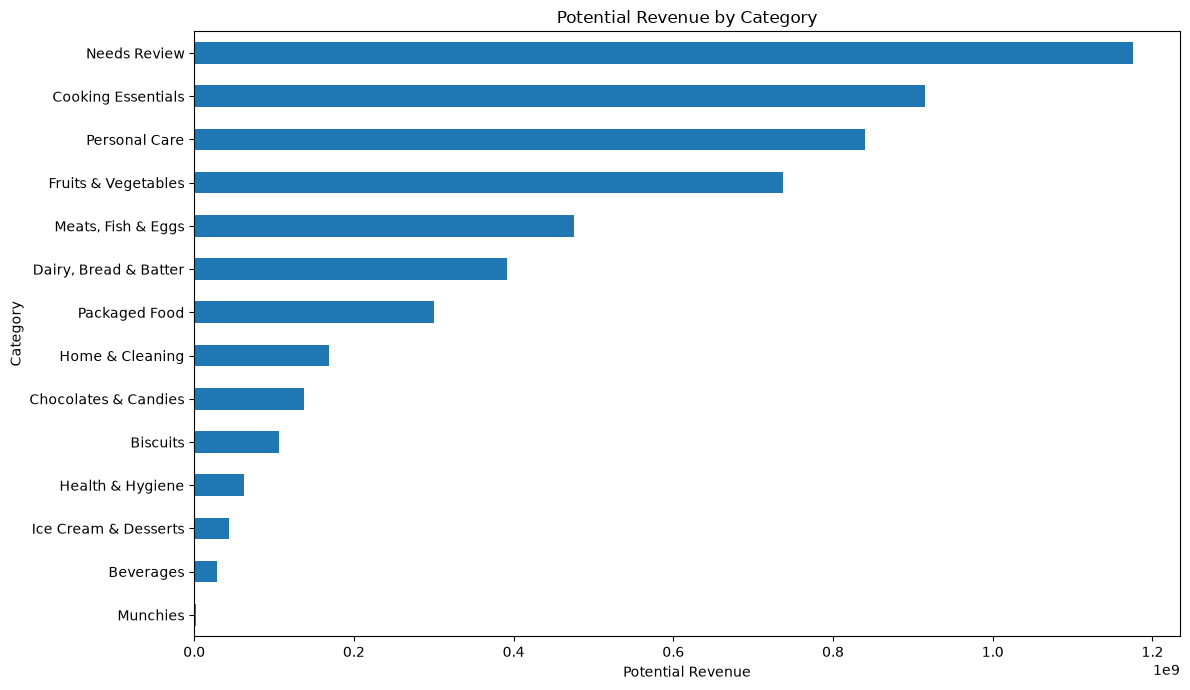

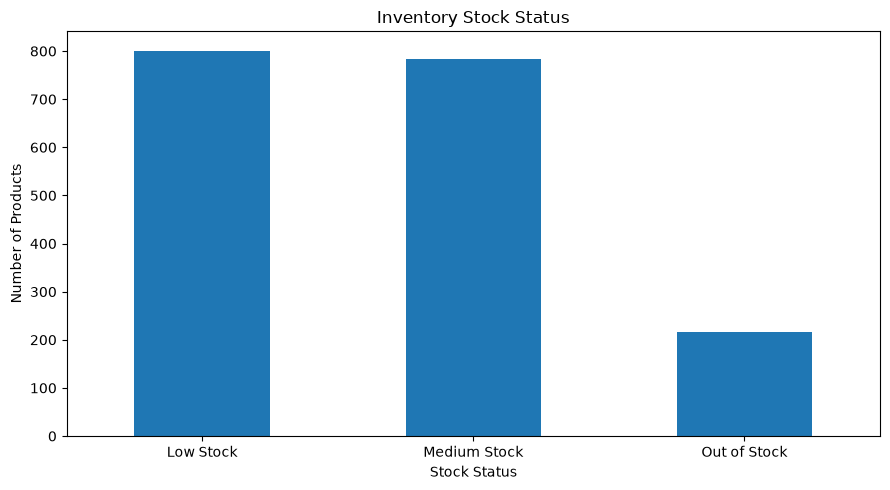

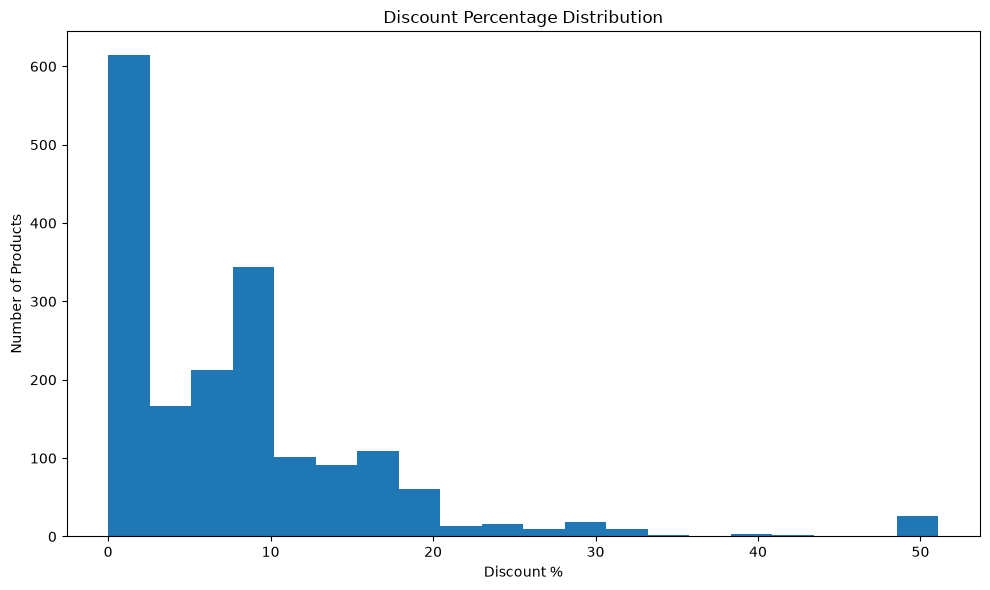

In [15]:
# ============================================================
# PYTHON EDA VISUALS
# ============================================================

# 1. Potential Revenue by Category

(
    category_summary['Potential_Revenue']
    .sort_values()
    .plot(
        kind='barh',
        figsize=(12, 7)
    )
)

plt.title('Potential Revenue by Category')
plt.xlabel('Potential Revenue')
plt.ylabel('Category')
plt.tight_layout()
plt.show()


# 2. Stock Status

df['Stock_Status'].value_counts().plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Inventory Stock Status')
plt.xlabel('Stock Status')
plt.ylabel('Number of Products')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 3. Discount Distribution

plt.figure(figsize=(10, 6))

plt.hist(
    df['Discount_%'],
    bins=20
)

plt.title('Discount Percentage Distribution')
plt.xlabel('Discount %')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# FINAL DATASET PREVIEW
# ============================================================

print("FINAL DATASET")
print("=" * 60)

print(f"Rows    : {len(df):,}")
print(f"Columns : {len(df.columns)}")

print("\nColumns:")

for i, column in enumerate(df.columns, 1):
    print(f"{i}. {column}")

display(df.head(10))

FINAL DATASET
Rows    : 1,801
Columns : 21

Columns:
1. Category
2. Product_Name
3. MRP
4. Discount_Percent
5. Available_Quantity
6. Selling_Price
7. Weight_Gms
8. Out_of_Stock
9. Quantity
10. Calculated_Discount_%
11. Discount_Difference
12. Corrected_Category
13. Discount_Amount
14. Discount_%
15. Potential_Revenue
16. Stock_Value
17. Weight_KG
18. Stock_Status
19. Discount_Band
20. Price_Band
21. Availability_Flag


,Category,Product_Name,MRP,Discount_Percent,Available_Quantity,Selling_Price,Weight_Gms,Out_of_Stock,Quantity,Calculated_Discount_%,Discount_Difference,Corrected_Category,Discount_Amount,Discount_%,Potential_Revenue,Stock_Value,Weight_KG,Stock_Status,Discount_Band,Price_Band,Availability_Flag
0,Fruits & Vegetables,Onion,2500,16,3,2100,1000,false,1,16.00,0.00,Fruits & Vegetables,400,16.00,2100,6300,1.00,Low Stock,10-20%,Budget,Available
1,Fruits & Vegetables,Tomato Hybrid,4200,16,3,3500,1000,false,1,16.67,0.67,Fruits & Vegetables,700,16.67,3500,10500,1.00,Low Stock,10-20%,Budget,Available
2,Fruits & Vegetables,Tender Coconut,5100,15,3,4300,58,false,1,15.69,0.69,Fruits & Vegetables,800,15.69,4300,12900,0.06,Low Stock,10-20%,Budget,Available
3,Fruits & Vegetables,Coriander Leaves,2000,15,3,1700,100,false,100,15.00,0.00,Fruits & Vegetables,300,15.00,170000,5100,0.10,Low Stock,10-20%,Budget,Available
4,Fruits & Vegetables,Ladies Finger,1400,14,3,1200,250,false,250,14.29,0.29,Fruits & Vegetables,200,14.29,300000,3600,0.25,Low Stock,10-20%,Budget,Available
5,Fruits & Vegetables,Potato,3500,17,3,2900,1000,false,1,17.14,0.14,Fruits & Vegetables,600,17.14,2900,8700,1.00,Low Stock,10-20%,Budget,Available
6,Fruits & Vegetables,Lemon,7500,16,3,6300,200,false,200,16.00,0.00,Fruits & Vegetables,1200,16.00,1260000,18900,0.20,Low Stock,10-20%,Mid-Range,Available
7,Fruits & Vegetables,Watermelon,5800,15,3,4900,58,false,1,15.52,0.52,Fruits & Vegetables,900,15.52,4900,14700,0.06,Low Stock,10-20%,Budget,Available
8,Fruits & Vegetables,Capsicum Green,2300,17,3,1900,250,false,250,17.39,0.39,Fruits & Vegetables,400,17.39,475000,5700,0.25,Low Stock,10-20%,Budget,Available
9,Fruits & Vegetables,Chilli Green,1900,15,3,1600,100,false,100,15.79,0.79,Fruits & Vegetables,300,15.79,160000,4800,0.10,Low Stock,10-20%,Budget,Available


In [17]:
# ============================================================
# EXPORT CLEAN DATA FOR SQL SERVER
# ============================================================

# Remove temporary validation columns
columns_to_remove = [
    'Calculated_Discount_%',
    'Discount_Difference'
]

df_sql = df.drop(
    columns=[
        col for col in columns_to_remove
        if col in df.columns
    ]
)

# Save Excel
df_sql.to_excel(
    'zepto_inventory_cleaned.xlsx',
    index=False
)

# Save CSV for SQL Server
df_sql.to_csv(
    'zepto_inventory_cleaned.csv',
    index=False
)

print("EXPORT SUCCESSFUL")
print("=" * 60)

print("Created files:")
print("1. zepto_inventory_cleaned.xlsx")
print("2. zepto_inventory_cleaned.csv")

print(f"\nFinal SQL dataset rows: {len(df_sql):,}")
print(f"Final SQL dataset columns: {len(df_sql.columns)}")

EXPORT SUCCESSFUL
Created files:
1. zepto_inventory_cleaned.xlsx
2. zepto_inventory_cleaned.csv

Final SQL dataset rows: 1,801
Final SQL dataset columns: 19


In [18]:
# ============================================================
# SQL-READY FINAL VALIDATION
# ============================================================

print("SQL-READY DATASET VALIDATION")
print("=" * 60)

print("Rows:", len(df_sql))
print("Columns:", len(df_sql.columns))
print("Duplicate rows:", df_sql.duplicated().sum())
print(
    "Unique products:",
    df_sql['Product_Name'].nunique()
)

print("\nMissing values:")
display(
    df_sql.isnull()
         .sum()
         .to_frame('Missing_Count')
)

print("\nSample final records:")
display(df_sql.head(10)
       )

SQL-READY DATASET VALIDATION
Rows: 1801
Columns: 19
Duplicate rows: 0
Unique products: 1674

Missing values:


,Missing_Count
Category,0
Product_Name,0
MRP,0
Discount_Percent,0
Available_Quantity,0
Selling_Price,0
Weight_Gms,0
Out_of_Stock,0
Quantity,0
Corrected_Category,0



Sample final records:


,Category,Product_Name,MRP,Discount_Percent,Available_Quantity,Selling_Price,Weight_Gms,Out_of_Stock,Quantity,Corrected_Category,Discount_Amount,Discount_%,Potential_Revenue,Stock_Value,Weight_KG,Stock_Status,Discount_Band,Price_Band,Availability_Flag
0,Fruits & Vegetables,Onion,2500,16,3,2100,1000,false,1,Fruits & Vegetables,400,16.00,2100,6300,1.00,Low Stock,10-20%,Budget,Available
1,Fruits & Vegetables,Tomato Hybrid,4200,16,3,3500,1000,false,1,Fruits & Vegetables,700,16.67,3500,10500,1.00,Low Stock,10-20%,Budget,Available
2,Fruits & Vegetables,Tender Coconut,5100,15,3,4300,58,false,1,Fruits & Vegetables,800,15.69,4300,12900,0.06,Low Stock,10-20%,Budget,Available
3,Fruits & Vegetables,Coriander Leaves,2000,15,3,1700,100,false,100,Fruits & Vegetables,300,15.00,170000,5100,0.10,Low Stock,10-20%,Budget,Available
4,Fruits & Vegetables,Ladies Finger,1400,14,3,1200,250,false,250,Fruits & Vegetables,200,14.29,300000,3600,0.25,Low Stock,10-20%,Budget,Available
5,Fruits & Vegetables,Potato,3500,17,3,2900,1000,false,1,Fruits & Vegetables,600,17.14,2900,8700,1.00,Low Stock,10-20%,Budget,Available
6,Fruits & Vegetables,Lemon,7500,16,3,6300,200,false,200,Fruits & Vegetables,1200,16.00,1260000,18900,0.20,Low Stock,10-20%,Mid-Range,Available
7,Fruits & Vegetables,Watermelon,5800,15,3,4900,58,false,1,Fruits & Vegetables,900,15.52,4900,14700,0.06,Low Stock,10-20%,Budget,Available
8,Fruits & Vegetables,Capsicum Green,2300,17,3,1900,250,false,250,Fruits & Vegetables,400,17.39,475000,5700,0.25,Low Stock,10-20%,Budget,Available
9,Fruits & Vegetables,Chilli Green,1900,15,3,1600,100,false,100,Fruits & Vegetables,300,15.79,160000,4800,0.10,Low Stock,10-20%,Budget,Available
